In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error

import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Dense

print(tf.__version__)

2.19.0


In [13]:
# Load dataset

df = pd.read_csv('train.csv')

print("Shape:", df.shape)
df.head()

Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


**PHASE 1: Ambitious Feature Engineering**

In [14]:
# Missing Values

missing = df.isnull().sum()
missing = missing[missing > 0]
print("Missing values:")
print(missing.sort_values(ascending=False))

Missing values:
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


In [15]:
# Handling missing values

for col in df.select_dtypes(include=['int64', 'float64']):
    df[col].fillna(df[col].median(), inplace=True)

for col in df.select_dtypes(include=['object']):
    df[col].fillna("None", inplace=True)

print("Missing values handled.")

Missing values handled.


/tmp/ipykernel_16431/202399193.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].median(), inplace=True)
/tmp/ipykernel_16431/202399193.py:7: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try us

In [16]:
# Feature Engineering

df['TotalArea'] = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']

df['HouseAge'] = df['YrSold'] - df['YearBuilt']

df['GarageAge'] = df['YrSold'] - df['GarageYrBlt']

In [17]:
# Log transform

y_raw = df['SalePrice']

df['SalePrice'] = np.log1p(df['SalePrice'])
y_log = df['SalePrice']

skewed = ['GrLivArea', 'LotArea']
for col in skewed:
    df[col] = np.log1p(df[col])

In [18]:
# Save neighborhood

neighborhood = df['Neighborhood']

In [19]:
df_onehot = pd.get_dummies(df)

In [20]:
# Embedding

df_label = df.copy()

for col in df_label.select_dtypes(include=['object']):
    df_label[col] = df_label[col].astype('category').cat.codes

**PHASE 2: Loss Function Experiment**

In [21]:
# Split data

X = df_onehot.drop('SalePrice', axis=1)

X_train, X_val, y_train_log, y_val_log = train_test_split(X, y_log, test_size=0.2, random_state=42)
_, _, y_train_raw, y_val_raw = train_test_split(X, y_raw, test_size=0.2, random_state=42)

In [22]:
# Normalise

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)

In [23]:
# Raw vs Log

def build_model():
    model = Sequential([
        Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
        Dense(32, activation='relu'),
        Dense(1)
    ])
    model.compile(optimizer='adam', loss='mse')
    return model

In [24]:
# Train Raw

model_raw = build_model()
history_raw = model_raw.fit(X_train, y_train_raw, validation_data=(X_val, y_val_raw), epochs=20, verbose=0)
pred_raw = model_raw.predict(X_val)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step


In [25]:
# Train Log

model_log = build_model()
history_log = model_log.fit(X_train, y_train_log, validation_data=(X_val, y_val_log), epochs=20, verbose=0)
pred_log = model_log.predict(X_val)

10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


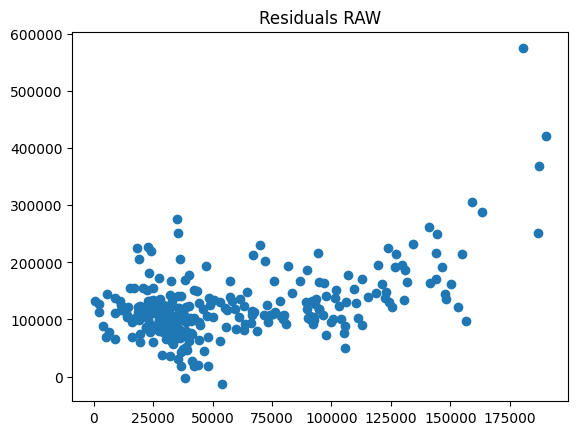

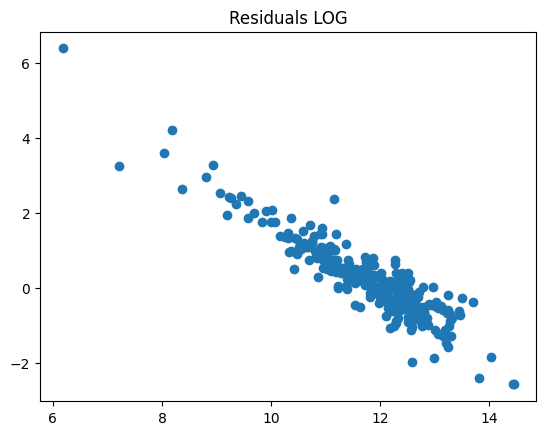

In [28]:
# Residual Plot

pred_raw = pred_raw.flatten()
pred_log = pred_log.flatten()

plt.scatter(pred_raw, y_val_raw - pred_raw)
plt.title("Residuals RAW")
plt.show()

plt.scatter(pred_log, y_val_log - pred_log)
plt.title("Residuals LOG")
plt.show()

**PHASE 3: Architecture Comparison**

In [30]:
# Linear model

lin = LinearRegression()
lin.fit(X_train, y_train_log)
pred_lin = lin.predict(X_val)

In [31]:
# Neural networks

def build_nn(layers):
    model = Sequential()
    model.add(Dense(64, activation='relu', input_shape=(X_train.shape[1],)))

    for _ in range(layers-1):
        model.add(Dense(32, activation='relu'))

    model.add(Dense(1))
    model.compile(optimizer='adam', loss='mse')
    return model

In [32]:
# Train models

model1 = build_nn(1)
model3 = build_nn(3)
model5 = build_nn(5)

h1 = model1.fit(X_train, y_train_log, validation_data=(X_val, y_val_log), epochs=20, verbose=0)
h3 = model3.fit(X_train, y_train_log, validation_data=(X_val, y_val_log), epochs=20, verbose=0)
h5 = model5.fit(X_train, y_train_log, validation_data=(X_val, y_val_log), epochs=20, verbose=0)

p1 = model1.predict(X_val)
p3 = model3.predict(X_val)
p5 = model5.predict(X_val)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step


In [33]:
# Metrics (MSE + MAPE)

def evaluate(y_true, pred):
    return mean_squared_error(y_true, pred), mean_absolute_percentage_error(y_true, pred)

print("Linear:", evaluate(y_val_log, pred_lin))
print("1-layer:", evaluate(y_val_log, p1))
print("3-layer:", evaluate(y_val_log, p3))
print("5-layer:", evaluate(y_val_log, p5))

Linear: (0.023120029101390428, 0.007529743199390021)
1-layer: (1.962998499919051, 0.07745737780053905)
3-layer: (1.0522572513339306, 0.06185184346116019)
5-layer: (1.3541358977257922, 0.06803183735095693)


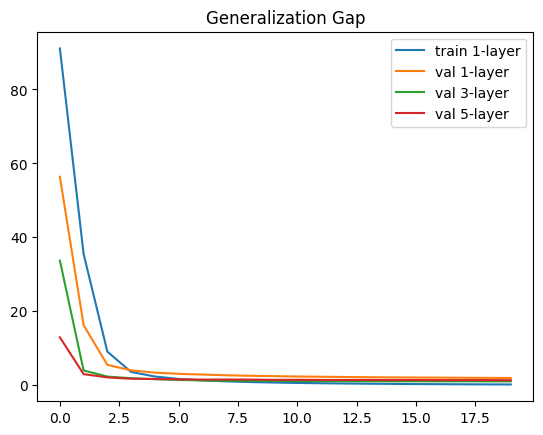

In [34]:
# Generalisation gap plot

plt.plot(h1.history['loss'], label="train 1-layer")
plt.plot(h1.history['val_loss'], label="val 1-layer")

plt.plot(h3.history['val_loss'], label="val 3-layer")
plt.plot(h5.history['val_loss'], label="val 5-layer")

plt.legend()
plt.title("Generalization Gap")
plt.show()

**PHASE 4: Representation Analysis**

In [37]:
# Extract hidden layer

_ = model3.predict(X_train)

hidden_model = Model(inputs=model3.inputs, outputs=model3.layers[1].output)

features = hidden_model.predict(X_val)

37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


In [38]:
# PCA

pca = PCA(n_components=2)
reduced = pca.fit_transform(features)

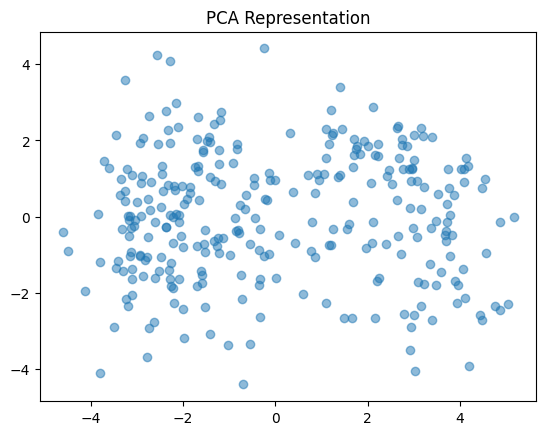

In [40]:
# PCA Plot

plt.scatter(reduced[:,0], reduced[:,1], alpha=0.5)
plt.title("PCA Representation")
plt.show()